# Task 4 – Addressable Market Ceiling

**Câu hỏi:** nếu một tỉnh được khai thác tốt như nhóm tỉnh tốt nhất, mỗi năm công ty có thể ký tối đa bao nhiêu contract ở đó, và phần của từng shop là bao nhiêu?

Luồng: external data -> map tỉnh -> contract theo tỉnh (gồm cross-sell) -> penetration
       -> benchmark -> ceiling tỉnh -> chia cho shop -> xuất file.
Mỗi bước có biểu đồ lưu ở OUT_DIR/figures.

| Bước | Nội dung | CSV xuất ra |
|---|---|---|
| 1 | Kiểm tra external data | `s1_external_checked.csv` |
| 2 | Bảng shop (gắn tỉnh, category) | `s2_shop_master.csv` |
| 3 | Gộp contract + lead về shop | `s3_shop_month.csv`, `s3_attribution_by_product.csv` |
| 4 | Contract trung bình năm theo tỉnh | `s4_province_current.csv` |
| 5 | Penetration | `s5_province_penetration.csv` |
| 6 | Benchmark và ceiling tỉnh | `s6_province_ceiling.csv`, `s6_benchmark_sensitivity.csv` |
| 7 | Chia ceiling cho shop | `s7_category_weights.csv`, `s7_shop_ceiling.csv` |

## Trước khi chạy notebook

Notebook được chuyển từ file script được cung cấp. Hãy kiểm tra cấu hình ở cell **0. CONFIG** trước khi chạy toàn bộ:

- `CLEAN_DIR`: thư mục chứa dữ liệu đã làm sạch (`salesroom`, `contract`, `leads`, và tùy chọn `shop_month`).
- `EXT_FILE`: đường dẫn tới CSV thống kê external theo 34 tỉnh mới.
- `OUT_DIR`: thư mục lưu CSV kết quả và biểu đồ.
- File external được giả định có 8 cột theo thứ tự: `province`, `year`, `area_km2`, `pop_k`, `density`, `workpop_k`, `retail_bn`, `income_k`.

## 0. Cấu hình

**Trung bình năm.** Mọi mức "trung bình" là trung bình năm:
$$Q_p = \frac{12}{|W|}\sum_{m \in W}\ \sum_{s \in p} n_{s,m}$$
với $W$ là cửa sổ đo (các tháng), $n_{s,m}$ là số contract credited cho shop $s$ trong tháng $m$, $p$ là tỉnh. Cột theo tháng ($=Q/12$) vẫn được xuất để khớp Current Actual ở Bước 1.

Cầu tín dụng tiêu dùng có mùa vụ (trước Tết, khai giảng, cuối năm). Trần thị trường là giới hạn *cấu trúc* của địa bàn, nên phải lấy trung bình nhiều tháng để không phụ thuộc quý cao điểm hay thấp điểm (cùng tinh thần "dân số trung bình năm" của thống kê).

**Vì sao cửa sổ 01–09/2026?** Bảng lead chỉ bắt đầu từ 31/12/2025. Contract vay tiền mặt, thẻ, BNPL ký online chỉ quy được về shop qua lead, nên trước 2026 phần này không quan sát được và sẽ làm penetration thấp giả tạo. Hạn chế: thiếu quý 4 (cao điểm), áp đều cho mọi tỉnh nên không đổi thứ hạng giữa các tỉnh. Nếu nhóm quyết định khác, chỉ cần sửa `WINDOW`.

In [1]:
import os, re, sys, unicodedata, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
warnings.filterwarnings("ignore")

CLEAN_DIR = Path(os.environ.get("CLEAN_DIR", "clean_data"))
EXT_FILE  = Path(os.environ.get("EXT_FILE", "clean_data/external_data.xlsx"))
OUT_DIR   = Path(os.environ.get("OUT_DIR", "task4_output"))
FIG_DIR, CSV_DIR = OUT_DIR / "figures", OUT_DIR / "csv"
for d in (FIG_DIR, CSV_DIR): d.mkdir(parents=True, exist_ok=True)

SIGNED_STATUS = ["Active", "Finished", "Paid off", "Written off", "Signed"]
WINDOW  = [f"2026-{m:02d}" for m in range(1, 10)]      # cửa sổ đo trung bình năm
ANNUAL  = 12
PRODUCT_MAP = {"REL": "CL", "CW": "CL"}                 # phải khớp với người làm Bước 1
BENCH_Q, BENCH_STAT = 0.75, "median"                    # benchmark = median của nhóm top 25% tỉnh ("avg" nếu muốn trung bình)
WEIGHT_MODE = "empirical"                               # hoặc "fixed"
FIXED_W = {"Big": 3, "Medium": 2, "Small": 1}

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9})
C_MAIN, C_ACC, C_GREY, C_GREEN = "#2F5D9E", "#E07B39", "#B8BEC8", "#6BA292"

con = duckdb.connect()
def sql(q, **tables):
    # Chạy SQL (DuckDB) trên các DataFrame truyền vào, trả về DataFrame
    for k, v in tables.items(): con.register(k, v)
    return con.execute(q).df()

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight"); plt.show()

def save_csv(df, name):
    df.to_csv(CSV_DIR / name, index=False, encoding="utf-8-sig"); print(f"-> csv/{name}  ({len(df):,} dòng)")

def show(df, n=8):
    try: display(df.head(n))
    except NameError: print(df.head(n).to_string())

def pick(df, cands, required=True):
    low = {c.lower(): c for c in df.columns}
    for c in cands:
        if c.lower() in low: return low[c.lower()]
    if required: raise KeyError(f"Không thấy cột nào trong {cands}. Cột hiện có: {list(df.columns)}")

def read_any(p):
    p = Path(p)
    if p.suffix == ".parquet": return pd.read_parquet(p)
    if p.suffix in (".xlsx", ".xls"): return pd.read_excel(p)
    return pd.read_csv(p, low_memory=False)

def find_file(keyword, exclude=()):
    hits = [p for p in CLEAN_DIR.rglob("*") if p.suffix.lower() in (".parquet", ".csv", ".xlsx")
            and keyword in p.name.lower() and not any(x in p.name.lower() for x in exclude)]
    return sorted(hits)[0] if hits else None

def norm(s):
    # chỉ để NỐI tên tỉnh với external: bỏ dấu, bỏ tiền tố TP./Tỉnh, bỏ ký tự lạ
    s = str(s).lower().replace("đ", "d")
    s = "".join(ch for ch in unicodedata.normalize("NFD", s) if unicodedata.category(ch) != "Mn")
    s = re.sub(r"^(tp|thanh pho|tinh)\b\.?\s*", "", s.strip())
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]", " ", s)).strip()

## Bước 1. External data theo tỉnh: kiểm tra và đặc trưng hoá

**Mục tiêu.** Biến bảng thống kê tỉnh thành các đại lượng dùng được cho ceiling và kiểm tra chất lượng trước khi dùng.

**Công thức.** Với tỉnh $p$ có dân số $N_p$, dân số tuổi lao động $L_p$, diện tích $A_p$, bán lẻ $R_p$, thu nhập bình quân đầu người $y_p$:
$$\theta_p=\frac{L_p}{N_p},\qquad r_p=\frac{R_p}{N_p},\qquad \text{density}_p=\frac{N_p}{A_p}$$
$\theta_p$ là tỷ lệ tuổi lao động, $r_p$ là bán lẻ bình quân đầu người (triệu đồng/người/năm).

- **$L_p$ (dân số tuổi lao động)** là quy mô nhóm khách hàng tiềm năng: người vay tiêu dùng chủ yếu là người có thu nhập. Đề dùng "người trưởng thành", nhưng không có số dân ≥15 theo tỉnh nên $L_p$ là đại diện.
- **$y_p$ (thu nhập)** phản ánh khả năng trả nợ và sức mua.
- **$R_p$ (bán lẻ + dịch vụ)** là quy mô tiêu dùng tổng thể, mà tín dụng tiêu dùng "bám" vào (mua điện thoại, xe máy, dịch vụ).
- **Mật độ** là mức đô thị hoá, ảnh hưởng chi phí phục vụ và độ dày mạng lưới shop.

Kiểm tra: mật độ tính lại phải khớp mật độ cho sẵn; $\theta_p$ không được lệch bất thường so với các tỉnh khác.

In [2]:
ext = read_any(EXT_FILE).iloc[:, :8]
ext.columns = ["province", "year", "area_km2", "pop_k", "density", "workpop_k", "retail_bn", "income_k"]
ext["pkey"] = ext["province"].map(norm)
assert len(ext) == 34 and ext.pkey.is_unique, "Cần đúng 34 tỉnh, không trùng"

E = sql('''
SELECT province, pkey, pop_k, workpop_k, area_km2, density, retail_bn, income_k,
       workpop_k * 1.0 / pop_k                         AS workpop_share,      -- theta
       retail_bn * 1.0 / pop_k                         AS retail_per_cap_mn,  -- r (triệu đồng/người/năm)
       ABS(pop_k * 1000.0 / area_km2 / density - 1)    AS density_err
FROM ext
''', ext=ext)
save_csv(E, "s1_external_checked.csv")
show(E)

-> csv/s1_external_checked.csv  (34 dòng)


,province,pkey,pop_k,workpop_k,area_km2,density,retail_bn,income_k,workpop_share,retail_per_cap_mn,density_err
0,Cao Bằng,cao bang,562.93,234.64,6700.39,84.01,11094.7,3144.87,0.416819,19.708845,5.371489e-05
1,Điện Biên,dien bien,667.42,352.01,9539.93,69.96,24313.9,3721.87,0.527419,36.429684,9.734894e-06
2,Lai Châu,lai chau,501.16,236.84,9068.73,55.26,8939.4,4099.67,0.472584,17.837417,4.386057e-05
3,Sơn La,son la,1341.22,625.17,14108.89,95.06,37602.4,4747.64,0.466120,28.035967,2.156039e-05
4,Tuyên Quang,tuyen quang,1748.25,768.47,13795.50,126.73,53647.3,5522.20,0.439565,30.686286,3.072407e-05
5,Gia Lai,gia lai,3182.65,1830.85,21576.53,147.51,190554.3,6097.12,0.575260,59.872842,3.265735e-05
6,Lạng Sơn,lang son,820.63,336.52,8310.18,98.75,41209.0,6497.12,0.410075,50.216297,3.351083e-07
7,Lào Cai,lao cai,1675.67,786.13,13256.92,126.40,59587.8,6560.27,0.469144,35.560582,2.797679e-06


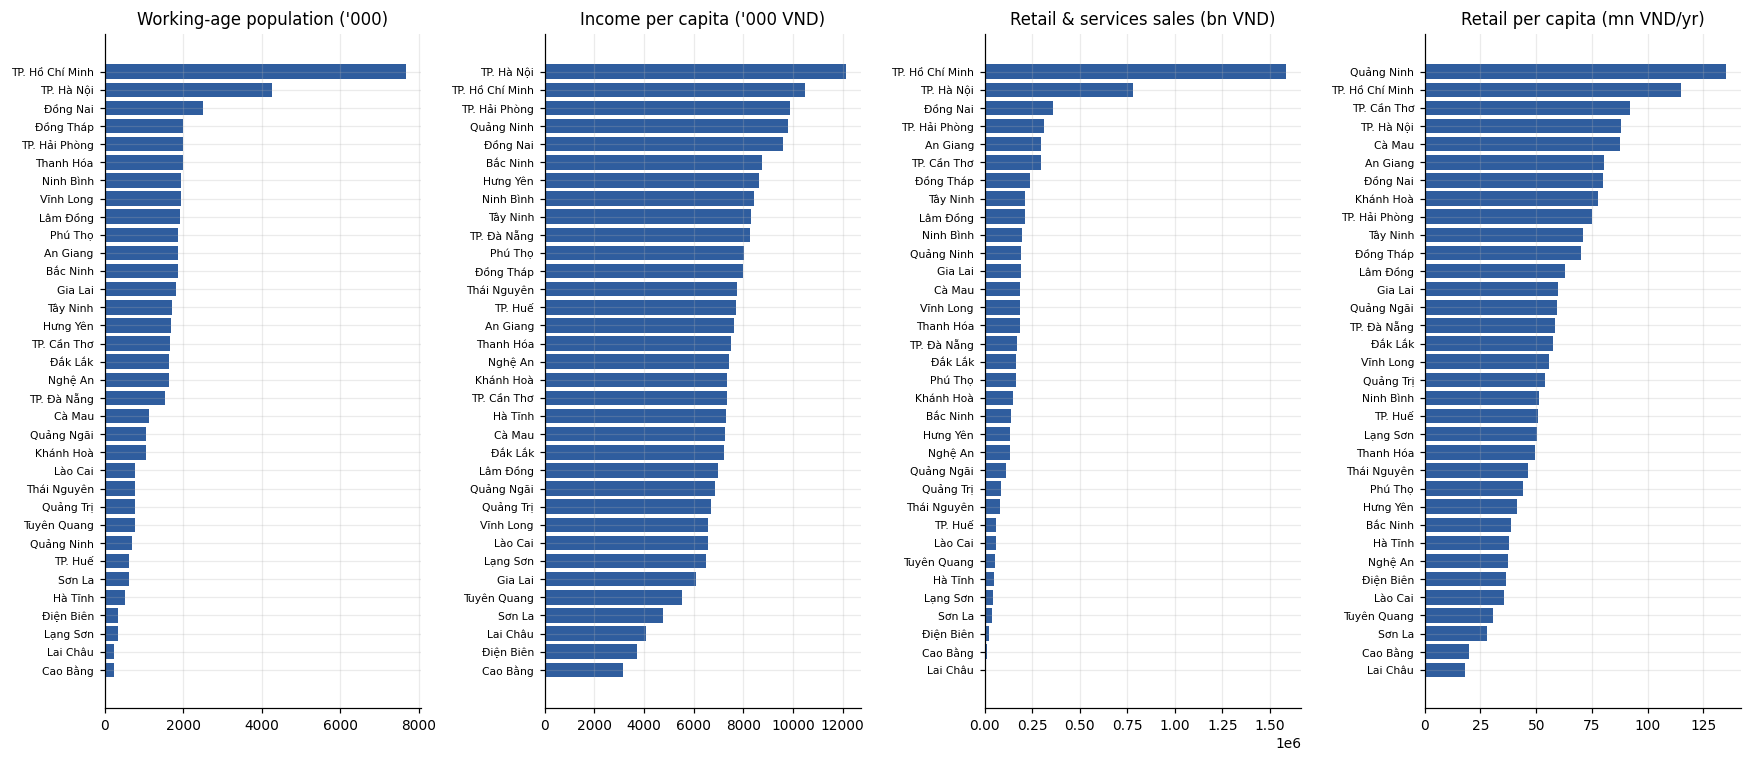

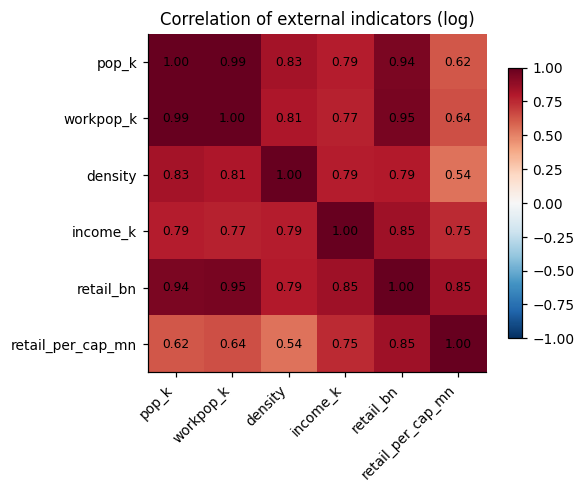

INSIGHT 1
- 5 tỉnh đông dân tuổi lao động nhất (TP. Hồ Chí Minh, TP. Hà Nội, Đồng Nai, Đồng Tháp, TP. Hải Phòng) chiếm 34% tổng cả nước: cầu tập trung vào vài đô thị lớn.
- Bán lẻ/người cao nhất: Quảng Ninh (135 triệu/người/năm), thấp nhất: Lai Châu (18); gấp 7.6 lần -> sức mua rất chênh lệch.
- Sai số mật độ lớn nhất: 0.01%. Tỷ lệ tuổi lao động thấp nhất: Hà Tĩnh (40%), Lạng Sơn (41%), Cao Bằng (42%) so với median 52% -> kiểm tra định nghĩa ở nguồn.


In [3]:
fig, axs = plt.subplots(1, 4, figsize=(16, 7))
for ax, (col, ttl) in zip(axs, [("workpop_k", "Working-age population ('000)"), ("income_k", "Income per capita ('000 VND)"),
                                ("retail_bn", "Retail & services sales (bn VND)"), ("retail_per_cap_mn", "Retail per capita (mn VND/yr)")]):
    d = E.sort_values(col); ax.barh(d.province, d[col], color=C_MAIN); ax.set_title(ttl); ax.tick_params(axis="y", labelsize=7)
savefig("s1_fig1_external_indicators")

cols = ["pop_k", "workpop_k", "density", "income_k", "retail_bn", "retail_per_cap_mn"]
cm = np.log(E[cols]).corr()
fig, ax = plt.subplots(figsize=(5.5, 4.5)); im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha="right"); ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)): ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Correlation of external indicators (log)"); plt.colorbar(im, shrink=.8); savefig("s1_fig2_external_corr")

top5 = E.nlargest(5, "workpop_k"); lo = E.nsmallest(3, "workpop_share")
print("INSIGHT 1")
print(f"- 5 tỉnh đông dân tuổi lao động nhất ({', '.join(top5.province)}) chiếm {top5.workpop_k.sum()/E.workpop_k.sum():.0%} tổng cả nước: cầu tập trung vào vài đô thị lớn.")
print(f"- Bán lẻ/người cao nhất: {E.nlargest(1,'retail_per_cap_mn').province.iloc[0]} ({E.retail_per_cap_mn.max():.0f} triệu/người/năm), thấp nhất: "
      f"{E.nsmallest(1,'retail_per_cap_mn').province.iloc[0]} ({E.retail_per_cap_mn.min():.0f}); gấp {E.retail_per_cap_mn.max()/E.retail_per_cap_mn.min():.1f} lần -> sức mua rất chênh lệch.")
print(f"- Sai số mật độ lớn nhất: {E.density_err.max():.2%}. Tỷ lệ tuổi lao động thấp nhất: {', '.join(f'{r.province} ({r.workpop_share:.0%})' for r in lo.itertuples())}"
      f" so với median {E.workpop_share.median():.0%} -> kiểm tra định nghĩa ở nguồn.")

## Bước 2. Bảng shop (shop master)

**Mục tiêu.** Gắn mỗi shop với tỉnh (đã là tỉnh sau sáp nhập), category, trạng thái; xác định shop vật lý và shop online.

**Công thức (phép nối).** $\text{ShopMaster} = \text{Salesroom} \bowtie_{\,pkey}\text{External}$ (nối nhiều–một, mỗi shop một tỉnh). Tập shop vật lý $S_{phys}=\{s:\text{category}_s\ne \text{Virtual}\}$; tập đánh giá $S_{act}=\{s\in S_{phys}:\text{status}_s=\text{Active}\}$.

Shop vật lý có *vùng phục vụ* (catchment area) gắn với địa bàn nên mới gắn được với cầu của tỉnh; shop online phục vụ khách mọi nơi nên không thể chia theo tỉnh (đề cũng yêu cầu xét riêng). Shop đã đóng vẫn được giữ trong `S_phys` để contract lịch sử của nó được tính đúng vào tỉnh, nhưng không nhận ceiling.

In [4]:
sr = read_any(find_file("salesroom", exclude=("emp_2",)))
c_id, c_cat = pick(sr, ["skp_salesroom"]), pick(sr, ["salesroom_category", "category"])
c_st, c_pv = pick(sr, ["salesroom_status", "status"]), pick(sr, ["salesroom_province", "province", "province_new"])
c_start = pick(sr, ["salesroom_start", "start_date"], required=False)
sr = sr.drop_duplicates(c_id).rename(columns={c_id: "shop", c_cat: "category", c_st: "status", c_pv: "province_raw"})
sr["start"] = pd.to_datetime(sr[c_start], errors="coerce") if c_start else pd.NaT
fix_dict = {
    "hcm": "ho chi minh",
    "tphcm": "ho chi minh",
}
sr["pkey"] = sr["province_raw"].map(norm).replace(fix_dict)
sr["is_physical"] = (sr["category"].str.lower() != "virtual").astype(int)
sr["is_active"] = (sr["status"].str.lower() == "active").astype(int)

SM = sql('''
SELECT s.shop, s.category, s.status, s.start, s.is_physical, s.is_active, s.pkey, e.province
FROM sr s LEFT JOIN ext e ON s.pkey = e.pkey
''', sr=sr, ext=ext)
unm = SM[SM.province.isna() & (SM.is_physical == 1)]
print(f"{len(SM):,} shop | vật lý: {SM.is_physical.sum():,} | Active vật lý: {((SM.is_physical==1)&(SM.is_active==1)).sum():,} | "
      f"vật lý chưa khớp tỉnh external: {len(unm):,}")
if len(unm): print("Tên tỉnh chưa khớp (kiểm tra chính tả/tên cũ):\n", sr.loc[sr.shop.isin(unm.shop), "province_raw"].value_counts().head(10))
save_csv(SM, "s2_shop_master.csv")
phys = SM[(SM.is_physical == 1) & SM.province.notna()].copy()

14,216 shop | vật lý: 14,111 | Active vật lý: 11,752 | vật lý chưa khớp tỉnh external: 0
-> csv/s2_shop_master.csv  (14,216 dòng)


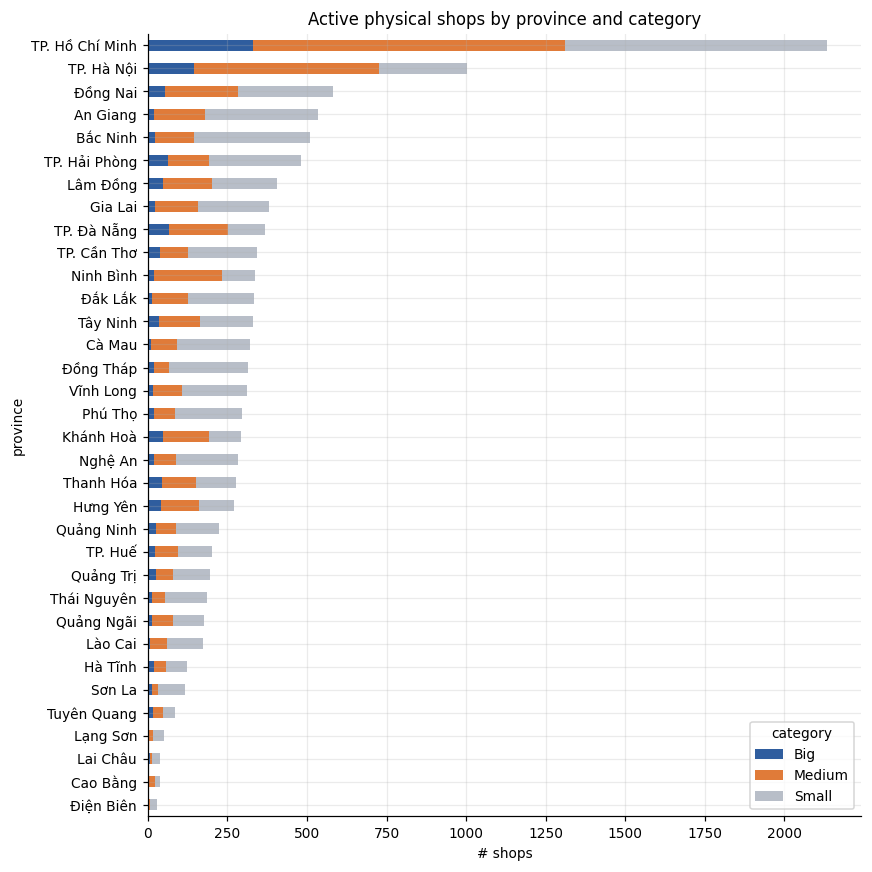

INSIGHT 2
- 11,752 shop Active vật lý; 5 tỉnh nhiều shop nhất: TP. Hồ Chí Minh, TP. Hà Nội, Đồng Nai, An Giang, Bắc Ninh (41% tổng).
- Cơ cấu category: Big 11%, Medium 38%, Small 52% -> shop nhỏ chiếm đa số, nên cách chia trần theo category (Bước 7) quan trọng.
- Tỉnh ít shop nhất: Điện Biên (29), Cao Bằng (38), Lai Châu (39) -> độ tin cậy thấp khi so sánh nội bộ tỉnh.


In [5]:
t = (sql('''SELECT province, category, COUNT(*) AS n FROM phys WHERE is_active = 1 GROUP BY province, category''', phys=phys)
     .pivot(index="province", columns="category", values="n").fillna(0))
t = t.loc[t.sum(axis=1).sort_values().index]
t.plot.barh(stacked=True, figsize=(8, 8), color=[C_MAIN, C_ACC, C_GREY, C_GREEN][:t.shape[1]])
plt.title("Active physical shops by province and category"); plt.xlabel("# shops"); savefig("s2_fig1_shops_by_province")

tot = t.sum(axis=1)
print("INSIGHT 2")
print(f"- {int(tot.sum()):,} shop Active vật lý; 5 tỉnh nhiều shop nhất: {', '.join(tot.nlargest(5).index)} ({tot.nlargest(5).sum()/tot.sum():.0%} tổng).")
print(f"- Cơ cấu category: " + ", ".join(f"{c} {t[c].sum()/tot.sum():.0%}" for c in t.columns) +
      " -> shop nhỏ chiếm đa số, nên cách chia trần theo category (Bước 7) quan trọng.")
print(f"- Tỉnh ít shop nhất: {', '.join(f'{k} ({int(v)})' for k, v in tot.nsmallest(3).items())} -> độ tin cậy thấp khi so sánh nội bộ tỉnh.")

## Bước 3. Gộp contract và lead về shop (credited contracts)

**Mục tiêu.** Quy mỗi contract đã ký về đúng một shop, gồm cả contract ký online nhưng do shop tạo ra cơ hội (cross-sell).

**Công thức.** Với contract $c$ (khách $k_c$, sản phẩm $g_c$, nộp lúc $t_c$, ký tại $h_c$), tập lead khớp
$$\mathcal{L}_c=\{\,l:\ k_l=k_c,\ g_l=g_c,\ t^{assign}_l\le t_c\,\}$$
Shop được ghi công:
$$\sigma(c)=\begin{cases}h_c & h_c\in S_{phys}\quad(\text{direct})\\ s_{l^*}\ \text{với}\ l^*=\arg\max_{l\in\mathcal{L}_c}t^{assign}_l & h_c\notin S_{phys},\ \mathcal{L}_c\ne\emptyset\quad(\text{cross-sell})\\ \text{không ai} & \text{còn lại}\end{cases}$$
Mỗi contract được tính **một lần**, nên tổng không bị đếm trùng.

 Đây là bài toán **phân bổ công trạng (attribution)** trong kênh phân phối đa kênh: nếu chỉ đếm nơi ký, shop vật lý bị đánh thấp vì CL/CC/BNPL gần như chỉ ghi ở mã online. Chọn lead giao *gần nhất trước* ngày nộp hồ sơ vì người tiếp cận khách sau cùng nhiều khả năng là người thúc đẩy quyết định (last-touch attribution). Đây là quy ước, không phải sự thật nhân quả; cần ghi rõ ở slide.

**Cách chạy.** Nếu nhóm đã có bảng `shop_month` từ Bước 1 (file chứa "shop_month" trong `clean_data`, cột `skp_salesroom, month, contracts_direct, contracts_xsell`, tuỳ chọn `funded_volume`) notebook dùng bảng đó để cả nhóm cùng số liệu. Nếu không, tự gộp bằng DuckDB.

In [6]:
XSELL_SQL = '''
WITH direct AS (
    -- Ghi nhận Direct cho Shop vật lý nơi hợp đồng trực tiếp phát sinh
    SELECT cc, shop_c AS shop, ds, prod, amt, 'direct' AS src 
    FROM c 
    WHERE shop_c IN (SELECT shop FROM phys_ids)
),
cand AS (
    -- Tìm Lead phù hợp để ghi nhận Cross-sell cho Shop đã tạo Lead
    SELECT c.cc, l.shop_l AS shop, c.ds, c.prod, c.amt,
           ROW_NUMBER() OVER (PARTITION BY c.cc ORDER BY l.dassign DESC) AS rn
    FROM c 
    JOIN l ON c.cl = l.cl 
           AND c.prod = l.prod 
           AND l.dassign >= c.da - INTERVAL 30 DAY       -- Lead trong vòng 30 ngày trước khi apply
           AND l.dassign <= c.da + INTERVAL 1 HOUR       -- Đệm 1 giờ cho độ trễ đồng bộ
    WHERE c.shop_c != l.shop_l                           -- Cho phép Cross-sell giữa các shop khác nhau (kể cả giữa 2 shop vật lý)
),
xs AS (
    -- Chọn Lead mới nhất gần thời điểm apply nhất
    SELECT cc, shop, ds, prod, amt, 'xsell' AS src 
    FROM cand 
    WHERE rn = 1
),
u AS (
    SELECT * FROM direct 
    UNION ALL 
    SELECT * FROM xs
)
SELECT shop, 
       substr(CAST(ds AS VARCHAR), 1, 7) AS month, 
       prod, 
       src, 
       COUNT(*) AS n, 
       SUM(amt) AS funded
FROM u 
GROUP BY 1, 2, 3, 4
'''

def credit_with_duckdb(phys_ids):
    cpath, lpath = find_file("contract", exclude=("product",)), find_file("lead", exclude=("reason",))
    assert cpath and lpath, "Không thấy contract/leads trong CLEAN_DIR"
    rd = lambda p: f"read_parquet('{p}')" if p.suffix == ".parquet" else f"read_csv_auto('{p}')"
    case = lambda col: "CASE " + " ".join(f"WHEN {col} = '{k}' THEN '{v}'" for k, v in PRODUCT_MAP.items()) + f" ELSE {col} END"
    st = ",".join(f"'{s}'" for s in SIGNED_STATUS)
    con.register("phys_ids", pd.DataFrame({"shop": phys_ids}))
    con.execute(f'''CREATE OR REPLACE VIEW c AS SELECT skp_credit_case AS cc, skp_client AS cl, skp_salesroom AS shop_c,
        {case('product')} AS prod, CAST(date_apply AS TIMESTAMP) AS da, CAST(COALESCE(date_sign, date_apply) AS TIMESTAMP) AS ds,
        credit_amount AS amt FROM {rd(cpath)} WHERE name_status IN ({st})''')
    con.execute(f'''CREATE OR REPLACE VIEW l AS SELECT skp_client AS cl, {case('code_product_type')} AS prod,
        CAST(date_assigned AS TIMESTAMP) AS dassign, skp_salesroom AS shop_l FROM {rd(lpath)}
        WHERE skp_salesroom IN (SELECT shop FROM phys_ids)''')
    credited = con.execute(XSELL_SQL).df()
    total = con.execute("SELECT substr(CAST(ds AS VARCHAR),1,7) AS month, prod, COUNT(*) AS n_total FROM c GROUP BY 1,2").df()
    return credited, total

def shop_month_from_file(p):
    d = read_any(p)
    out = pd.DataFrame({"shop": d[pick(d, ["skp_salesroom", "shop"])],
                        "month": pd.to_datetime(d[pick(d, ["month", "year_month", "ym"])]).dt.to_period("M").astype(str)})
    cd, cx = pick(d, ["contracts_direct", "n_direct"], False), pick(d, ["contracts_xsell", "contracts_cross_sell", "n_xsell"], False)
    if cd and cx: out["direct"], out["xsell"] = d[cd].values, d[cx].values
    else: out["direct"], out["xsell"] = d[pick(d, ["contracts", "n_contracts", "contracts_total"])].values, 0
    fc = pick(d, ["funded_volume", "funded", "funded_total"], False); out["funded"] = d[fc].values if fc else np.nan
    return out

credited = total = None
sm_path = find_file("shop_month")
if sm_path is not None:
    print("Dùng shop_month từ Bước 1:", sm_path.name); shop_month = shop_month_from_file(sm_path)
else:
    print("Không có shop_month -> tự gộp contract + leads bằng DuckDB")
    credited, total = credit_with_duckdb(phys.shop.tolist())
    shop_month = sql('''
        SELECT shop, month,
               SUM(CASE WHEN src = 'direct' THEN n ELSE 0 END) AS direct,
               SUM(CASE WHEN src = 'xsell'  THEN n ELSE 0 END) AS xsell,
               SUM(funded) AS funded
        FROM credited GROUP BY shop, month''', credited=credited)

shop_month = sql('''
    SELECT m.shop, m.month, m.direct, m.xsell, m.direct + m.xsell AS contracts, m.funded
    FROM shop_month m JOIN phys p ON m.shop = p.shop''', shop_month=shop_month, phys=phys)   # chỉ shop vật lý đã gắn tỉnh
save_csv(shop_month, "s3_shop_month.csv")
show(shop_month)

Không có shop_month -> tự gộp contract + leads bằng DuckDB


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

-> csv/s3_shop_month.csv  (67,075 dòng)


,shop,month,direct,xsell,contracts,funded
0,95886574,2025-07,32.0,0.0,32.0,174449000.0
1,97682457,2025-04,2.0,0.0,2.0,36000000.0
2,115096301,2025-12,4.0,0.0,4.0,102480000.0
3,106938080,2026-03,3.0,0.0,3.0,29800000.0
4,103863162,2025-08,4.0,0.0,4.0,14500000.0
5,102107270,2026-02,1.0,0.0,1.0,3400000.0
6,119503479,2026-06,2.0,0.0,2.0,32500000.0
7,109032077,2026-04,7.0,0.0,7.0,55360000.0


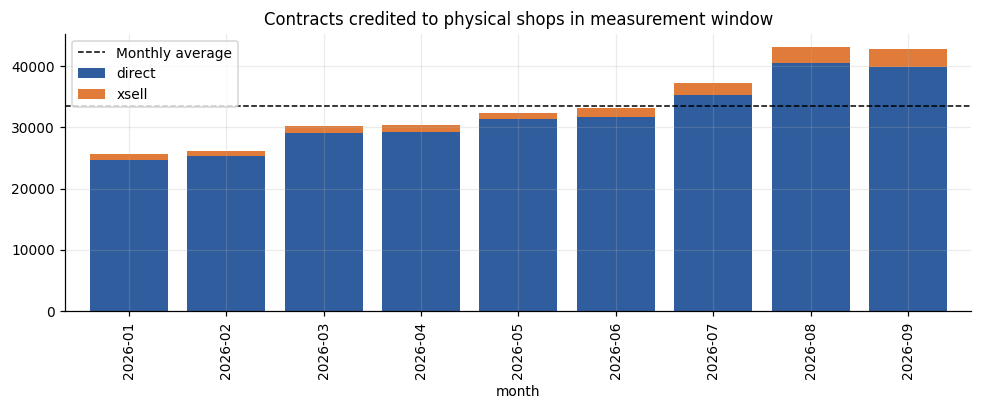

-> csv/s3_attribution_by_product.csv  (5 dòng)


src,prod,direct,xsell,unattributed
0,BNPL,9.5,0.0,90.5
1,CC,7.2,5.1,87.6
2,CD,100.0,0.3,0.0
3,CL,3.0,1.1,96.0
4,TW,33.2,0.9,65.9


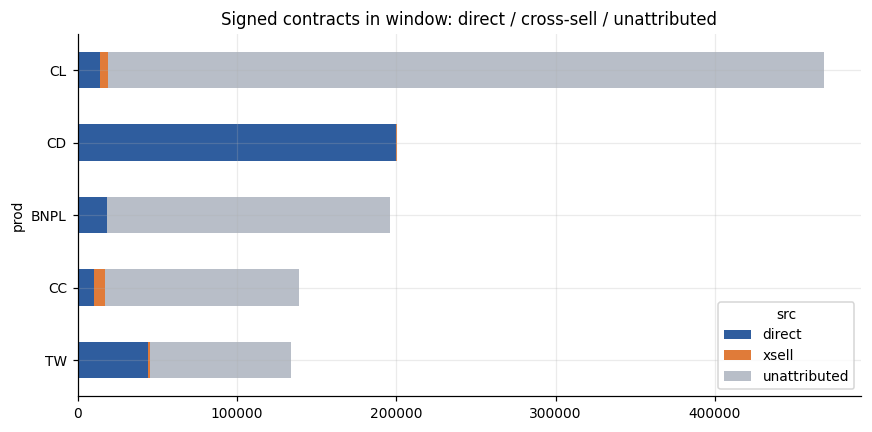

INSIGHT 3
- Cross-sell chiếm 5% contract credited cho shop vật lý trong cửa sổ đo. Phần cross-sell nhỏ, kết quả ít nhạy với cách quy công trạng.
- Biến động tháng: cao nhất/thấp nhất = 1.69 lần -> mùa vụ đáng kể, cần trung bình nhiều tháng.
- Tỷ lệ không quy được về shop nào (theo sản phẩm, %): {'BNPL': 90.5, 'CC': 87.6, 'CD': 0.0, 'CL': 96.0, 'TW': 65.9}


In [7]:
mm = sql(f"SELECT month, SUM(direct) AS direct, SUM(xsell) AS xsell FROM shop_month WHERE month IN ({','.join(repr(m) for m in WINDOW)}) GROUP BY month ORDER BY month",
         shop_month=shop_month).set_index("month")
ax = mm.plot.bar(stacked=True, figsize=(9, 3.8), color=[C_MAIN, C_ACC], width=.8)
ax.axhline(mm.sum(axis=1).mean(), color="k", ls="--", lw=1, label="Monthly average"); ax.legend()
ax.set_title("Contracts credited to physical shops in measurement window"); savefig("s3_fig1_monthly_contracts")

if credited is not None:
    w = credited[credited.month.isin(WINDOW)].pivot_table(index="prod", columns="src", values="n", aggfunc="sum", fill_value=0)
    tt = total[total.month.isin(WINDOW)].groupby("prod").n_total.sum()
    w = w.reindex(tt.index).fillna(0); w["unattributed"] = (tt - w.sum(axis=1)).clip(lower=0)
    att = (w.div(tt, axis=0) * 100).round(1).reset_index(); save_csv(att, "s3_attribution_by_product.csv"); show(att)
    w.loc[tt.sort_values().index].plot.barh(stacked=True, figsize=(8, 4), color=[C_MAIN, C_ACC, C_GREY])
    plt.title("Signed contracts in window: direct / cross-sell / unattributed"); savefig("s3_fig2_attribution_by_product")

sh = mm.xsell.sum() / mm.sum().sum()
print("INSIGHT 3")
print(f"- Cross-sell chiếm {sh:.0%} contract credited cho shop vật lý trong cửa sổ đo. "
      f"{'Nếu bỏ qua cross-sell, giá trị shop bị đánh thấp tương ứng.' if sh > .05 else 'Phần cross-sell nhỏ, kết quả ít nhạy với cách quy công trạng.'}")
print(f"- Biến động tháng: cao nhất/thấp nhất = {mm.sum(axis=1).max()/mm.sum(axis=1).min():.2f} lần -> "
      f"{'mùa vụ đáng kể, cần trung bình nhiều tháng' if mm.sum(axis=1).max()/mm.sum(axis=1).min() > 1.2 else 'ít mùa vụ trong cửa sổ'}.")
if credited is not None:
    print("- Tỷ lệ không quy được về shop nào (theo sản phẩm, %):", att.set_index('prod').unattributed.to_dict())

## Bước 4. Contract trung bình năm theo tỉnh (Current, phía cung đã thực hiện)

**Mục tiêu.** Tính số contract thực tế mỗi năm của từng tỉnh, gồm cả cross-sell: $Q_p$ (và funded volume $F_p$).

**Công thức.**
$$Q_p=\frac{12}{|W|}\sum_{m\in W}\sum_{s\in S_p} n_{s,m},\qquad F_p=\frac{12}{|W|}\sum_{m\in W}\sum_{s\in S_p} f_{s,m}$$
với $S_p$ là các shop vật lý của tỉnh $p$ (kể cả shop đã đóng) và $f_{s,m}$ là tổng `CREDIT_AMOUNT`.

$Q_p$ là **cầu đã được thoả mãn** ở tỉnh (quantity demanded tại mức giá và mạng lưới hiện có), tức *revealed demand*. Nó là sàn của trần: không thể nói thị trường chỉ đủ cho ít hơn số đang bán. Tỉnh không có shop nào ghi contract nhận $Q_p=0$ (trần chỉ dựa vào benchmark).

In [8]:
win = ",".join(repr(m) for m in WINDOW)
PC = sql(f'''
WITH agg AS (
  SELECT p.pkey, SUM(m.contracts) AS n, SUM(m.xsell) AS n_x, SUM(m.funded) AS f
  FROM shop_month m JOIN phys p ON m.shop = p.shop
  WHERE m.month IN ({win}) GROUP BY p.pkey)
SELECT e.province, e.pkey, e.pop_k, e.workpop_k, e.income_k, e.retail_bn, e.density,
       COALESCE(a.n, 0)   * {ANNUAL} * 1.0 / {len(WINDOW)} AS current_pa,
       COALESCE(a.n_x, 0) * {ANNUAL} * 1.0 / {len(WINDOW)} AS current_xsell_pa,
       COALESCE(a.f, 0)   * {ANNUAL} * 1.0 / {len(WINDOW)} AS current_funded_pa
FROM ext e LEFT JOIN agg a ON e.pkey = a.pkey
''', shop_month=shop_month, phys=phys, ext=ext)
save_csv(PC, "s4_province_current.csv"); show(PC.sort_values("current_pa", ascending=False))

-> csv/s4_province_current.csv  (34 dòng)


,province,pkey,pop_k,workpop_k,income_k,retail_bn,density,current_pa,current_xsell_pa,current_funded_pa
17,TP. Hồ Chí Minh,ho chi minh,13803.79,7681.98,10472.08,1585693.0,2038.18,93788.000000,5173.333333,1.499964e+12
28,TP. Hà Nội,ha noi,8857.53,4259.15,12133.15,780610.2,2636.30,40308.000000,2212.000000,6.150057e+11
18,Đồng Nai,dong nai,4493.69,2509.15,9606.37,359674.8,352.80,32846.666667,1570.666667,4.871649e+11
29,An Giang,an giang,3694.59,1864.85,7601.14,297837.2,373.61,20038.666667,798.666667,2.550238e+11
2,TP. Cần Thơ,can tho,3224.94,1676.77,7331.34,296542.4,507.00,16089.333333,734.666667,2.271285e+11
23,Khánh Hoà,khanh hoa,1898.55,1047.48,7334.36,147866.2,221.90,13420.000000,456.000000,1.921562e+11
25,Bắc Ninh,bac ninh,3572.35,1859.50,8738.03,138346.5,757.08,12340.000000,644.000000,1.532649e+11
20,TP. Đà Nẵng,da nang,2856.38,1531.58,8252.63,167487.6,240.85,12038.666667,480.000000,1.609885e+11


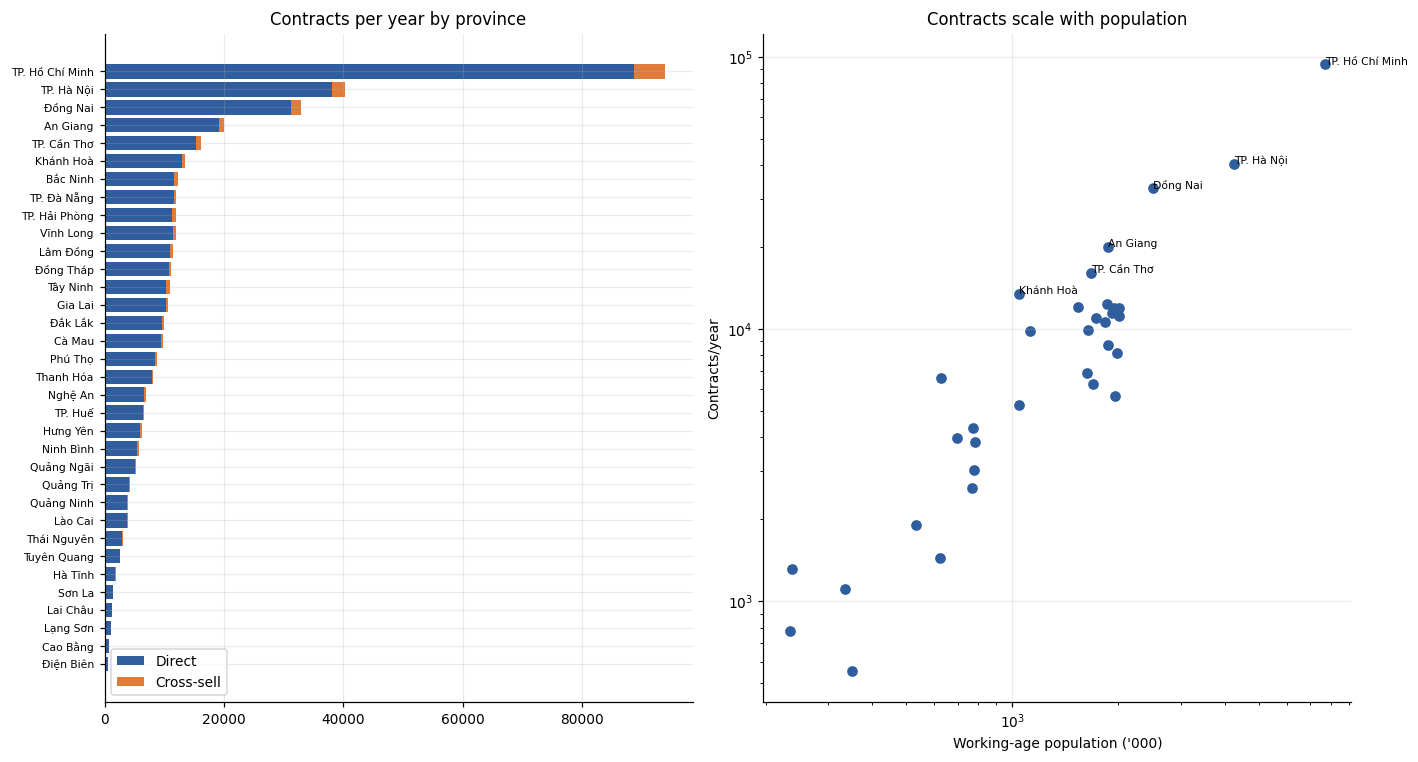

INSIGHT 4
- Tổng 401,243 contract/năm; 5 tỉnh đầu (TP. Hồ Chí Minh, TP. Hà Nội, Đồng Nai, An Giang, TP. Cần Thơ) chiếm 51%; HHI tỉnh = 0.087.
- Tỉnh chưa có contract credited: không có.
- Quy mô thị trường cho thấy: tỉnh đông dân bán nhiều (tương quan log-log dân số/contract = 0.93); vì vậy phải chuẩn hoá theo dân số (Bước 5) mới so sánh công bằng.


In [9]:
d = PC.sort_values("current_pa")
fig, axs = plt.subplots(1, 2, figsize=(13, 7))
axs[0].barh(d.province, d.current_pa - d.current_xsell_pa, color=C_MAIN, label="Direct")
axs[0].barh(d.province, d.current_xsell_pa, left=d.current_pa - d.current_xsell_pa, color=C_ACC, label="Cross-sell")
axs[0].set_title("Contracts per year by province"); axs[0].legend(); axs[0].tick_params(axis="y", labelsize=7)
axs[1].scatter(PC.workpop_k, PC.current_pa, color=C_MAIN)
for r in PC.nlargest(6, "current_pa").itertuples(): axs[1].annotate(r.province, (r.workpop_k, r.current_pa), fontsize=7)
axs[1].set_xscale("log"); axs[1].set_yscale("log"); axs[1].set_xlabel("Working-age population ('000)"); axs[1].set_ylabel("Contracts/year")
axs[1].set_title("Contracts scale with population")
savefig("s4_fig1_province_current")

s = PC.current_pa.sort_values(ascending=False); sh_ = s / s.sum()
print("INSIGHT 4")
print(f"- Tổng {PC.current_pa.sum():,.0f} contract/năm; 5 tỉnh đầu ({', '.join(PC.loc[s.index[:5], 'province'])}) chiếm {sh_.iloc[:5].sum():.0%}; HHI tỉnh = {(sh_**2).sum():.3f}.")
print(f"- Tỉnh chưa có contract credited: {', '.join(PC[PC.current_pa==0].province) or 'không có'}.")
print(f"- Quy mô thị trường cho thấy: tỉnh đông dân bán nhiều (tương quan log-log dân số/contract = {np.corrcoef(np.log(PC.workpop_k), np.log(PC.current_pa.clip(lower=1)))[0,1]:.2f}); "
      "vì vậy phải chuẩn hoá theo dân số (Bước 5) mới so sánh công bằng.")

## Bước 5. Penetration (mức thâm nhập thị trường)

**Mục tiêu.** So sánh các tỉnh khác nhau về quy mô trên cùng một thước đo.

**Công thức.**
$$\pi_p=\frac{Q_p}{L_p}\ \ (\text{contract/năm trên 1.000 người tuổi lao động}),\qquad \rho_p=\frac{Q_p}{R_p/100}\ \ (\text{contract/năm trên 100 tỷ đồng bán lẻ})$$
Độ co giãn theo thu nhập (hồi quy log-log):
$$\ln \pi_p=\alpha+\beta\,\ln y_p+\varepsilon_p$$
$\beta$ là phần trăm penetration tăng khi thu nhập tăng 1%.

- $\pi_p$ là **thị phần theo đầu người** của công ty trong "ví tín dụng tiêu dùng" của địa phương. Hai tỉnh bán cùng số contract nhưng dân số khác nhau thì mức khai thác khác nhau.
- $\beta$ là **độ co giãn theo thu nhập** của cầu. $\beta>0$ nghĩa là hàng tiêu dùng trả góp là hàng thông thường (thu nhập cao thì mua nhiều). $\beta<1$ gợi ý bão hoà (hiệu ứng giảm dần). $\beta\approx0$ hoặc âm cho thấy penetration chủ yếu do **phía cung** (công ty mở shop và đưa SA vào đâu) chứ không phải do cầu, và là cảnh báo cho benchmark ở Bước 6.
- $\rho_p$ đo theo tiêu dùng thay vì dân số, dùng để kiểm tra chéo.

-> csv/s5_province_penetration.csv  (34 dòng)


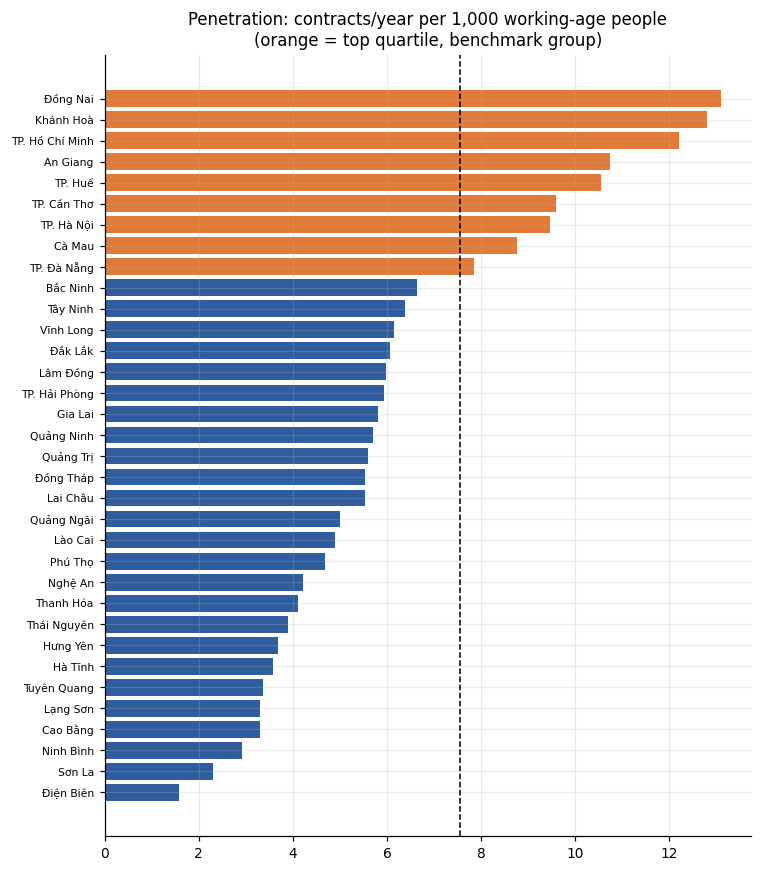

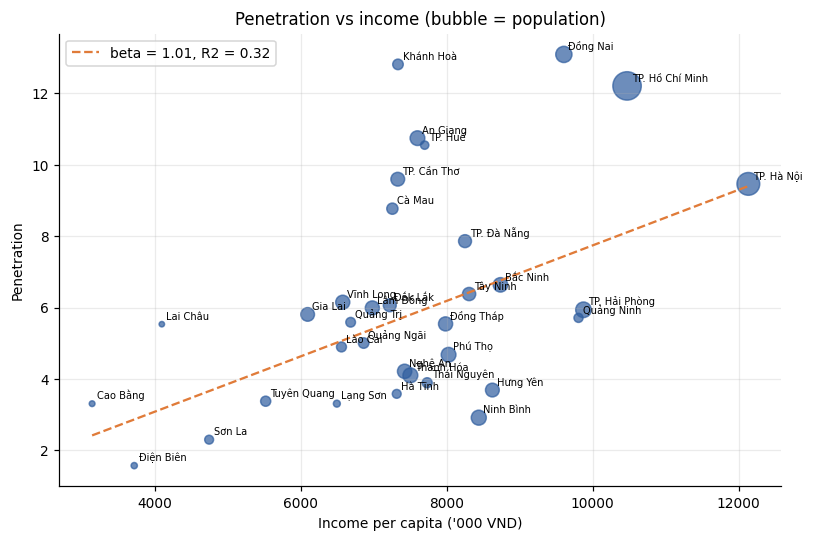

INSIGHT 5
- Penetration cao nhất: Đồng Nai, Khánh Hoà, TP. Hồ Chí Minh; thấp nhất: Điện Biên, Sơn La, Ninh Bình; chênh 8.3 lần.
- Độ co giãn theo thu nhập beta = 1.01 (R2 = 0.32): tăng nhanh hơn thu nhập (hàng xa xỉ tương đối).
- Tương quan hạng (Spearman) của penetration với mật độ: 0.48.


In [10]:
P = sql('''
SELECT *, current_pa / workpop_k AS pen, current_pa / (retail_bn / 100.0) AS pen_retail,
          current_funded_pa / NULLIF(current_pa, 0) AS avg_ticket
FROM PC''', PC=PC)
save_csv(P[["province", "workpop_k", "income_k", "retail_bn", "current_pa", "pen", "pen_retail", "avg_ticket"]], "s5_province_penetration.csv")
thr = float(P.pen.quantile(BENCH_Q))

d = P.sort_values("pen"); fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(d.province, d.pen, color=np.where(d.pen >= thr, C_ACC, C_MAIN)); ax.axvline(thr, color="k", ls="--", lw=1)
ax.set_title("Penetration: contracts/year per 1,000 working-age people\n(orange = top quartile, benchmark group)"); ax.tick_params(axis="y", labelsize=7)
savefig("s5_fig1_penetration_rank")

ok = P.pen > 0
b1, a1 = np.polyfit(np.log(P.income_k[ok]), np.log(P.pen[ok]), 1)
resid = np.log(P.pen[ok]) - (a1 + b1 * np.log(P.income_k[ok])); r2 = 1 - resid.var() / np.log(P.pen[ok]).var()
fig, ax = plt.subplots(figsize=(7.5, 5)); ax.scatter(P.income_k, P.pen, s=P.pop_k / 40, color=C_MAIN, alpha=.7)
for r in P.itertuples(): ax.annotate(r.province, (r.income_k, r.pen), fontsize=6.5, xytext=(3, 3), textcoords="offset points")
xs = np.linspace(P.income_k.min(), P.income_k.max(), 50); ax.plot(xs, np.exp(a1 + b1 * np.log(xs)), color=C_ACC, ls="--", label=f"beta = {b1:.2f}, R2 = {r2:.2f}")
ax.legend(); ax.set_xlabel("Income per capita ('000 VND)"); ax.set_ylabel("Penetration"); ax.set_title("Penetration vs income (bubble = population)")
savefig("s5_fig2_penetration_vs_income")

rho = P[["pen", "income_k", "density"]].corr(method="spearman").pen
print("INSIGHT 5")
print(f"- Penetration cao nhất: {', '.join(P.nlargest(3,'pen').province)}; thấp nhất: {', '.join(P.nsmallest(3,'pen').province)}; "
      f"chênh {P.pen.max()/max(P.pen[P.pen>0].min(),1e-9):.1f} lần.")
print(f"- Độ co giãn theo thu nhập beta = {b1:.2f} (R2 = {r2:.2f}): " +
      ("penetration tăng theo thu nhập nhưng chậm hơn thu nhập (bão hoà)." if 0 < b1 < 1 else
       "tăng nhanh hơn thu nhập (hàng xa xỉ tương đối)." if b1 >= 1 else
       "không tăng theo thu nhập -> penetration nhiều khả năng do phía cung (mạng lưới shop), cần thận trọng khi dùng làm benchmark."))
print(f"- Tương quan hạng (Spearman) của penetration với mật độ: {rho['density']:.2f}.")

## Nhận xét:
- Các tỉnh Top đầu đều là thủ phủ công nghiệp (Đồng Nai, TP.HCM) hoặc dịch vụ/du lịch (Khánh Hòa). Dân nhập cư nhiều, lao động phổ thông, công nhân nhà máy đông — đây chính là "mỏ vàng" truyền thống của vay tiêu dùng. Ngược lại, Điện Biên, Sơn La là tỉnh miền núi (nông nghiệp, phân tán), Ninh Bình mang nặng văn hóa Bắc Bộ (tâm lý tiết kiệm, sợ nợ nần, ngại rủi ro).
- Khi thu nhập người dân tăng 1%, nhu cầu vay trả góp tăng nhiều hơn 1%. Điều này chứng tỏ người dân không vay để "ăn no mặc ấm" (nhu cầu thiết yếu), mà vay để "nâng cấp đời sống" (mua iPhone đời mới nhất, đổi xe SH máy lạnh, mua tivi to hơn). Thu nhập chỉ giải thích được 32% lý do người ta vay. 68% còn lại phụ thuộc vào các yếu tố khác (khuyến mãi, độ phủ của nhân viên sale, văn hóa vùng miền). Do đó, chỉ bơm tiền vào nơi giàu là chưa đủ.
- Nơi nào dân cư sống càng "đặc", công ty càng dễ kiếm hợp đồng. Lý do là vì ở nơi đông đúc: (1) Số lượng điểm bán lẻ (Thế Giới Di Động, FPT...) dày đặc giúp nhân viên sale dễ chốt đơn; (2) Hiệu ứng truyền miệng mạnh; (3) Chi phí vận hành, thu hồi nợ (collection) tính trên đầu người rẻ hơn rất nhiều so với vùng thưa dân.

## Bước 6. Benchmark và Addressable Market Ceiling của tỉnh

**Mục tiêu.** Trả lời: tỉnh $p$ sẽ có bao nhiêu contract/năm nếu khai thác tốt như nhóm tỉnh dẫn đầu?

**Công thức.**
$$\pi^*=\operatorname{median}\{\pi_p:\ \pi_p\ge P_{75}(\pi)\},\qquad C_p=\max\big(\pi^*\cdot L_p,\ Q_p\big)$$
Phương pháp kiểm tra chéo theo bán lẻ: $\rho^*=\operatorname{median}\{\rho_p:\rho_p\ge P_{75}(\rho)\}$, $\ C^{R}_p=\max(\rho^*\cdot R_p/100,\ Q_p)$. Khoảng bất định: $[\min(C_p,C^R_p),\ \max(C_p,C^R_p)]$. Dư địa thị trường: $H_p=C_p-Q_p$.

- **Benchmark là đường biên thực hành tốt nhất (best-practice frontier).** Lấy median của nhóm top 25% thay vì tỉnh cao nhất để tránh ngoại lệ; đó là mức mà nhiều tỉnh khác điều kiện đã đạt được nên đủ thực tế.
- **Giả định hội tụ:** áp chung $\pi^*$ cho mọi tỉnh coi các tỉnh thấp là chưa bão hoà và sẽ "đuổi kịp". Chỉ hợp lý khi sức mua tương đương, nên có thêm phương pháp bán lẻ (tính theo quy mô tiêu dùng).
- **Sàn tại $Q_p$:** cầu đã bộc lộ không thể bị trần phủ định.
- **Rủi ro lẫn cung và cầu:** tỉnh top có thể cao vì công ty đầu tư nhiều shop và SA ở đó. Khi đó $\pi^*$ chứa cả sức cung, và ceiling các tỉnh khác bị thổi phồng. Vì vậy báo cả khoảng bất định và độ nhạy theo cách chọn benchmark.

In [11]:
agg_fn = "median" if BENCH_STAT == "median" else "avg"
bm = sql(f'''
SELECT (SELECT {agg_fn}(pen)        FROM P WHERE pen        >= (SELECT quantile_cont(pen, {BENCH_Q})        FROM P)) AS bench,
       (SELECT {agg_fn}(pen_retail) FROM P WHERE pen_retail >= (SELECT quantile_cont(pen_retail, {BENCH_Q}) FROM P)) AS bench_retail
''', P=P)
bench, bench_r = float(bm.bench[0]), float(bm.bench_retail[0])
print(f"Benchmark pi* = {bench:.3f} contract/năm/1.000 người tuổi lao động | rho* = {bench_r:.3f} contract/năm/100 tỷ bán lẻ")

PB = sql(f'''
SELECT *, GREATEST({bench} * workpop_k, current_pa)                 AS ceiling_pop,
          GREATEST({bench_r} * retail_bn / 100.0, current_pa)       AS ceiling_retail
FROM P''', P=P)
PB = sql('''
SELECT *, LEAST(ceiling_pop, ceiling_retail) AS ceiling_low, GREATEST(ceiling_pop, ceiling_retail) AS ceiling_high,
       ceiling_pop - current_pa AS headroom, ceiling_pop / NULLIF(current_pa, 0) AS ceiling_multiple
FROM PB''', PB=PB)
save_csv(PB[["province", "workpop_k", "current_pa", "pen", "ceiling_pop", "ceiling_retail", "ceiling_low", "ceiling_high", "headroom", "ceiling_multiple"]], "s6_province_ceiling.csv")

# độ nhạy theo cách chọn benchmark
cand = {"P75 (cutoff)": float(P.pen.quantile(.75)), "Top-quartile median": float(P[P.pen >= thr].pen.median()),
        "Top-quartile mean": float(P[P.pen >= thr].pen.mean()), "P90": float(P.pen.quantile(.90))}
sens = pd.DataFrame([{"benchmark": k, "pi_star": v,
                      "national_ceiling_pa": float(sql(f"SELECT SUM(GREATEST({v} * workpop_k, current_pa)) AS x FROM P", P=P).x[0])} for k, v in cand.items()])
sens["multiple_of_current"] = sens.national_ceiling_pa / P.current_pa.sum(); save_csv(sens, "s6_benchmark_sensitivity.csv"); show(sens)

Benchmark pi* = 10.550 contract/năm/1.000 người tuổi lao động | rho* = 8.920 contract/năm/100 tỷ bán lẻ
-> csv/s6_province_ceiling.csv  (34 dòng)
-> csv/s6_benchmark_sensitivity.csv  (4 dòng)


,benchmark,pi_star,national_ceiling_pa,multiple_of_current
0,P75 (cutoff),7.554267,480982.367057,1.198732
1,Top-quartile median,10.549651,586892.125416,1.462686
2,Top-quartile mean,10.566233,587562.970038,1.464358
3,P90,10.686716,592437.239119,1.476506


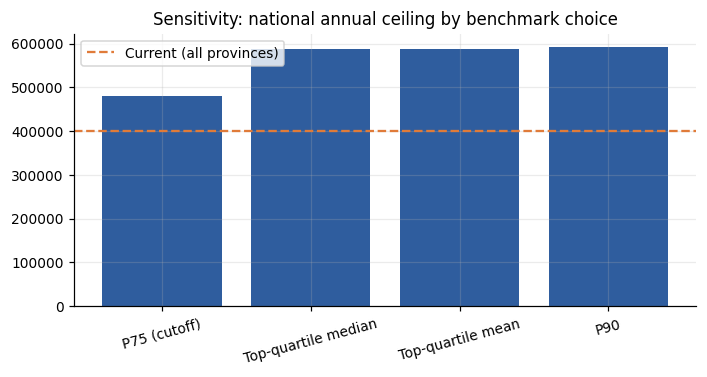

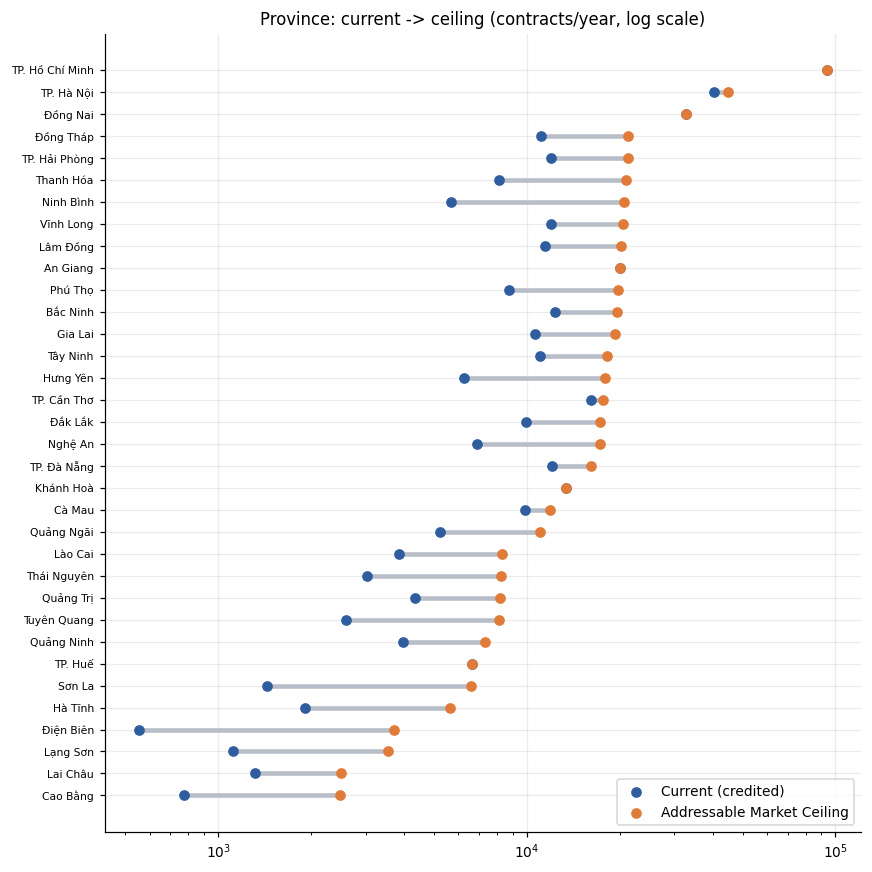

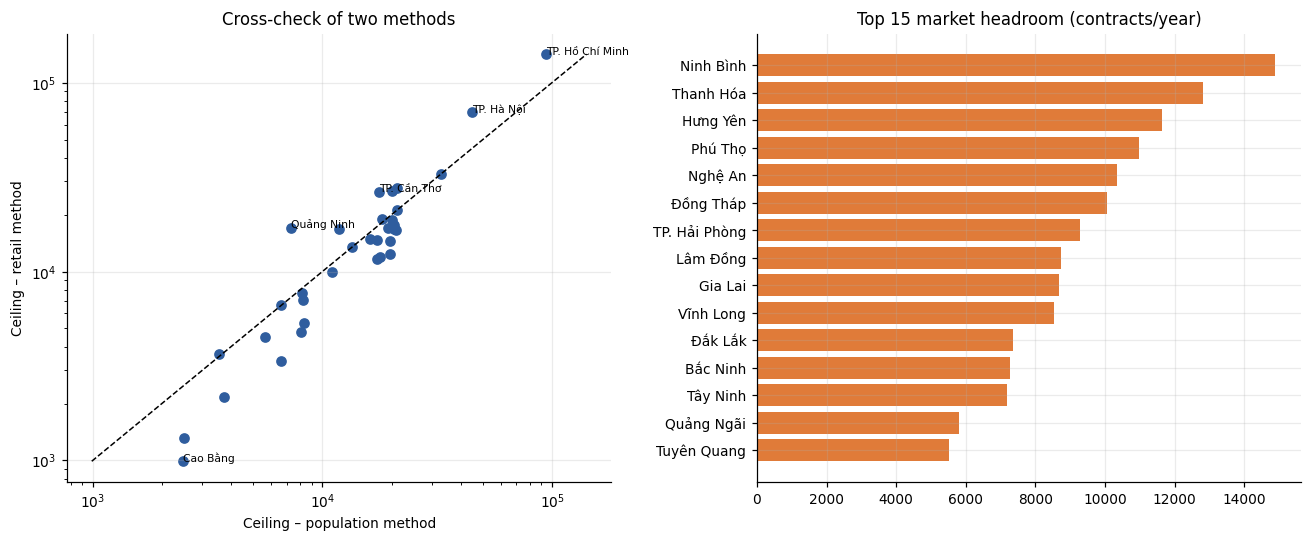

INSIGHT 6
- Ceiling toàn quốc = 586,892 contract/năm, gấp 1.46 lần Current. Theo cách chọn benchmark: 1.20–1.48 lần -> nên trình bày như một khoảng.
- Dư địa thị trường lớn nhất: Ninh Bình (+14,890), Thanh Hóa (+12,814), Hưng Yên (+11,645), Phú Thọ (+10,978), Nghệ An (+10,355); cộng 5 tỉnh này = 33% tổng dư địa.
- Số tỉnh đã ở sát trần (current ≥ 90% ceiling): 6 -> thị trường là ràng buộc ở đó, thêm nguồn lực ít hiệu quả.
- Hai phương pháp lệch nhiều nhất (retail/pop): Quảng Ninh (2.32x), Cao Bằng (0.40x), TP. Hà Nội (1.55x) -> sức mua của các tỉnh này khác xa quy mô dân số; diễn giải ceiling thận trọng.


In [12]:
fig, ax = plt.subplots(figsize=(6.5, 3.5)); ax.bar(sens.benchmark, sens.national_ceiling_pa, color=C_MAIN)
ax.axhline(P.current_pa.sum(), color=C_ACC, ls="--", label="Current (all provinces)"); ax.legend(); plt.xticks(rotation=15)
ax.set_title("Sensitivity: national annual ceiling by benchmark choice"); savefig("s6_fig1_benchmark_sensitivity")

d = PB.sort_values("ceiling_pop").reset_index(drop=True); fig, ax = plt.subplots(figsize=(8, 8))
ax.hlines(d.index, d.current_pa.clip(lower=1), d.ceiling_pop, color=C_GREY, lw=3)
ax.scatter(d.current_pa.clip(lower=1), d.index, color=C_MAIN, zorder=3, label="Current (credited)")
ax.scatter(d.ceiling_pop, d.index, color=C_ACC, zorder=3, label="Addressable Market Ceiling")
ax.set_yticks(d.index); ax.set_yticklabels(d.province, fontsize=7); ax.set_xscale("log"); ax.legend(loc="lower right")
ax.set_title("Province: current -> ceiling (contracts/year, log scale)"); savefig("s6_fig2_province_current_vs_ceiling")

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].scatter(PB.ceiling_pop, PB.ceiling_retail, color=C_MAIN); lim = [PB[["ceiling_pop", "ceiling_retail"]].min().min(), PB[["ceiling_pop", "ceiling_retail"]].max().max()]
axs[0].plot(lim, lim, "k--", lw=1); axs[0].set_xscale("log"); axs[0].set_yscale("log")
for r in PB.assign(gap=(PB.ceiling_retail / PB.ceiling_pop - 1).abs()).nlargest(5, "gap").itertuples(): axs[0].annotate(r.province, (r.ceiling_pop, r.ceiling_retail), fontsize=7)
axs[0].set_xlabel("Ceiling – population method"); axs[0].set_ylabel("Ceiling – retail method"); axs[0].set_title("Cross-check of two methods")
h = PB.nlargest(15, "headroom").sort_values("headroom"); axs[1].barh(h.province, h.headroom, color=C_ACC); axs[1].set_title("Top 15 market headroom (contracts/year)")
savefig("s6_fig3_crosscheck_and_headroom")

gap = (PB.ceiling_retail / PB.ceiling_pop)
print("INSIGHT 6")
print(f"- Ceiling toàn quốc = {PB.ceiling_pop.sum():,.0f} contract/năm, gấp {PB.ceiling_pop.sum()/PB.current_pa.sum():.2f} lần Current. Theo cách chọn benchmark: "
      f"{sens.multiple_of_current.min():.2f}–{sens.multiple_of_current.max():.2f} lần -> nên trình bày như một khoảng.")
print(f"- Dư địa thị trường lớn nhất: " + ", ".join(f"{r.province} (+{r.headroom:,.0f})" for r in PB.nlargest(5, 'headroom').itertuples()) +
      f"; cộng 5 tỉnh này = {PB.nlargest(5,'headroom').headroom.sum()/PB.headroom.sum():.0%} tổng dư địa.")
print(f"- Số tỉnh đã ở sát trần (current ≥ 90% ceiling): {(PB.current_pa >= .9 * PB.ceiling_pop).sum()} -> thị trường là ràng buộc ở đó, thêm nguồn lực ít hiệu quả.")
print(f"- Hai phương pháp lệch nhiều nhất (retail/pop): " + ", ".join(f"{r.province} ({gap[r.Index]:.2f}x)" for r in PB.loc[(gap-1).abs().nlargest(3).index].itertuples()) +
      " -> sức mua của các tỉnh này khác xa quy mô dân số; diễn giải ceiling thận trọng.")

## Bước 7. Chia ceiling của tỉnh cho từng shop

**Mục tiêu.** Đưa trần cấp tỉnh xuống cấp shop để dùng cho Bước 3, 5, 6.

**Công thức.** Với shop $s\in S_{act}$ thuộc tỉnh $p$, category $c(s)$, trọng số $w_c$:
$$\text{share}_s=\frac{w_{c(s)}}{\sum_{j\in S_{act}\cap p} w_{c(j)}},\qquad C_s=\max\big(C_p\cdot \text{share}_s,\ Q_s\big)$$
Trọng số thực nghiệm $w_c=\max\{P_{75}(Q_s:\ c(s)=c),\,1\}$ (toàn quốc); cột theo tháng $C_s/12$. Với shop mở giữa cửa sổ, $Q_s=\dfrac{12\sum_{m\in W} n_{s,m}}{\text{số tháng đã hoạt động trong }W}$.

Theo **lý thuyết địa điểm trung tâm (central place theory)**, shop lớn có vùng phục vụ rộng hơn và hút khách từ xa, nên trong cùng một tỉnh nó "chiếm" phần cầu lớn hơn shop nhỏ. Trọng số lấy theo *mức điển hình của loại shop* ($P_{75}$ theo category) thay vì theo số của chính shop để tránh lập luận vòng tròn (shop bán ít thì bị gán trần thấp, làm mất ý nghĩa tìm dư địa). Sàn tại $Q_s$ vì cầu đã bộc lộ không thể bị phủ định; hệ quả là tổng trần shop có thể vượt trần tỉnh một chút (được báo cáo).

Shop online (Virtual) không chia theo tỉnh, xử lý riêng như một nhóm ở các bước sau.

In [13]:
act = phys[phys.is_active == 1].copy()
w_start, w_end = pd.Period(WINDOW[0]).start_time, pd.Period(WINDOW[-1]).end_time
act["months_active"] = (((w_end - pd.to_datetime(act.start).clip(lower=w_start)).dt.days / 30.4).clip(lower=1, upper=len(WINDOW))
                        if act.start.notna().any() else len(WINDOW))
act["months_active"] = pd.to_numeric(act["months_active"]).fillna(len(WINDOW))

A = sql(f'''
SELECT a.shop, a.pkey, a.province, a.category, a.months_active,
       COALESCE(SUM(m.contracts), 0) * {ANNUAL} / a.months_active AS current_pa
FROM act a LEFT JOIN shop_month m ON m.shop = a.shop AND m.month IN ({win})
GROUP BY a.shop, a.pkey, a.province, a.category, a.months_active''', act=act, shop_month=shop_month)

if WEIGHT_MODE == "empirical":
    Wt = sql("SELECT category, GREATEST(quantile_cont(current_pa, 0.75), 1) AS w, COUNT(*) AS n_shops FROM A GROUP BY category", A=A)
else:
    Wt = pd.DataFrame({"category": list(FIXED_W), "w": list(FIXED_W.values()), "n_shops": np.nan})
save_csv(Wt, "s7_category_weights.csv"); show(Wt)

S = sql('''
WITH s AS (SELECT a.*, COALESCE(w.w, (SELECT MIN(w) FROM Wt)) AS w FROM A a LEFT JOIN Wt w ON a.category = w.category),
     t AS (SELECT s.*, s.w * 1.0 / SUM(s.w) OVER (PARTITION BY s.pkey) AS w_share FROM s)
SELECT t.shop, t.province, t.category, t.current_pa, t.months_active, t.w_share,
       t.w_share * p.ceiling_pop                                       AS ceiling_alloc,
       GREATEST(t.w_share * p.ceiling_pop, t.current_pa)               AS addressable_market_ceiling_pa,
       t.w_share * p.ceiling_low                                       AS ceiling_low_pa,
       t.w_share * p.ceiling_high                                      AS ceiling_high_pa
FROM t JOIN PB p ON p.pkey = t.pkey''', A=A, Wt=Wt, PB=PB)
S["current_exceeds_alloc"] = (S.current_pa > S.ceiling_alloc).astype(int)
S["addressable_market_ceiling_pm"] = S.addressable_market_ceiling_pa / ANNUAL
S["current_pm"] = S.current_pa / ANNUAL
S["is_new_shop"] = (S.months_active < 6).astype(int)
save_csv(S, "s7_shop_ceiling.csv"); show(S)

-> csv/s7_category_weights.csv  (3 dòng)


,category,w,n_shops
0,Small,34.870588,6063
1,Big,61.935824,1280
2,Medium,42.917647,4409


-> csv/s7_shop_ceiling.csv  (11,752 dòng)


,shop,province,category,current_pa,months_active,w_share,ceiling_alloc,addressable_market_ceiling_pa,ceiling_low_pa,ceiling_high_pa,current_exceeds_alloc,addressable_market_ceiling_pm,current_pm,is_new_shop
0,126306180,Cao Bằng,Medium,5.485714,4.375000,0.027245,67.440700,67.440700,26.961526,67.440700,0,5.620058,0.457143,1
1,102603598,Cao Bằng,Medium,1.341176,8.947368,0.027245,67.440700,67.440700,26.961526,67.440700,0,5.620058,0.111765,0
2,96005618,Cao Bằng,Small,4.023529,8.947368,0.022136,54.795568,54.795568,21.906240,54.795568,0,4.566297,0.335294,0
3,111082833,Cao Bằng,Medium,21.458824,8.947368,0.027245,67.440700,67.440700,26.961526,67.440700,0,5.620058,1.788235,0
4,126204290,Cao Bằng,Medium,2.251852,5.328947,0.027245,67.440700,67.440700,26.961526,67.440700,0,5.620058,0.187654,1
5,122581757,Cao Bằng,Medium,1.545763,7.763158,0.027245,67.440700,67.440700,26.961526,67.440700,0,5.620058,0.128814,0
6,126288033,Cao Bằng,Big,36.695858,5.559211,0.039318,97.325823,97.325823,38.909037,97.325823,0,8.110485,3.057988,1
7,99126136,Cao Bằng,Small,0.000000,8.947368,0.022136,54.795568,54.795568,21.906240,54.795568,0,4.566297,0.000000,0


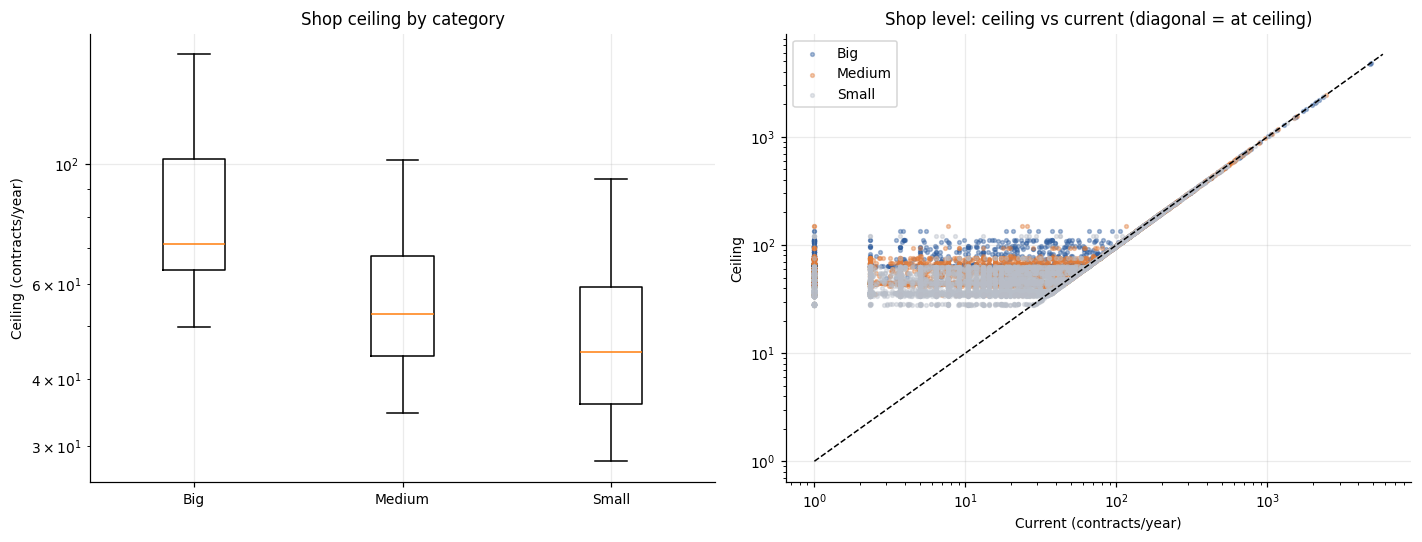

INSIGHT 7
- 11,752 shop Active được gán trần. 24% đã ≥90% trần (thị trường địa phương là ràng buộc); 22% có Current > phần được chia (trần được nâng lên bằng Current).
- Tổng trần shop vượt trần tỉnh 46.0% do sàn tại Current (tín hiệu: phép chia theo category chưa phản ánh hết khác biệt giữa shop cùng tỉnh).
- Trần trung vị theo category (contract/năm): Big 71, Medium 53, Small 45; Current trung vị: Big 16, Medium 12, Small 11.
- Shop mở dưới 6 tháng trong cửa sổ: 4,518 (độ tin cậy thấp, gắn nhãn 'shop mới' theo quy ước 5).


In [14]:
cats = [c for c in ["Big", "Medium", "Small"] if c in S.category.unique()]
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
axs[0].boxplot([S.loc[S.category == c, "addressable_market_ceiling_pa"] for c in cats], labels=cats, showfliers=False)
axs[0].set_yscale("log"); axs[0].set_ylabel("Ceiling (contracts/year)"); axs[0].set_title("Shop ceiling by category")
for c, col in zip(cats, [C_MAIN, C_ACC, C_GREY]):
    s_ = S[S.category == c]; axs[1].scatter(s_.current_pa + 1, s_.addressable_market_ceiling_pa, s=6, alpha=.4, label=c, color=col)
lim = [1, S.addressable_market_ceiling_pa.max() * 1.2]; axs[1].plot(lim, lim, "k--", lw=1); axs[1].set_xscale("log"); axs[1].set_yscale("log"); axs[1].legend()
axs[1].set_xlabel("Current (contracts/year)"); axs[1].set_ylabel("Ceiling"); axs[1].set_title("Shop level: ceiling vs current (diagonal = at ceiling)")
savefig("s7_fig1_shop_ceiling")

at = (S.current_pa >= .9 * S.addressable_market_ceiling_pa)
print("INSIGHT 7")
print(f"- {len(S):,} shop Active được gán trần. {at.mean():.0%} đã ≥90% trần (thị trường địa phương là ràng buộc); {S.current_exceeds_alloc.mean():.0%} có Current > phần được chia (trần được nâng lên bằng Current).")
print(f"- Tổng trần shop vượt trần tỉnh {S.addressable_market_ceiling_pa.sum()/S.ceiling_alloc.sum()-1:.1%} do sàn tại Current (tín hiệu: phép chia theo category chưa phản ánh hết khác biệt giữa shop cùng tỉnh).")
print("- Trần trung vị theo category (contract/năm): " + ", ".join(f"{c} {S.loc[S.category==c,'addressable_market_ceiling_pa'].median():,.0f}" for c in cats) +
      "; Current trung vị: " + ", ".join(f"{c} {S.loc[S.category==c,'current_pa'].median():,.0f}" for c in cats) + ".")
print(f"- Shop mở dưới 6 tháng trong cửa sổ: {S.is_new_shop.sum():,} (độ tin cậy thấp, gắn nhãn 'shop mới' theo quy ước 5).")